<center><h1>Xia_Iris_HW7</h1></center>

Name: 
<br> Iris Xia
Github Username: xd11997
<br>
USC ID: 1152659547

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import balanced_accuracy_score
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram


### (a) Download the Anuran Calls (MFCCs) Data Set

In [4]:
df = pd.read_csv("./data/Frogs_MFCCs.csv")

df.columns = df.columns.str.strip().str.replace(" ", "", regex=False)
X = df[[f"MFCCs_{i}" for i in range(1, 23)]]
y = df[["Family", "Genus", "Species"]]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(5036, 22) (2159, 22)
(5036, 3) (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

**Exact-match accuracy** is the proportion of instances for which all three labels—Family, Genus, and Species—are predicted correctly. **Hamming loss** is the proportion of individual labels predicted incorrectly; a lower value is better. **Hamming score** equals one minus the Hamming loss, so a higher value is better. We use these metrics to evaluate the classifiers on the test set. 

#### (ii) Train a SVM for each of the labels

In [13]:
labels = ["Family", "Genus", "Species"]

param_grid = {
    "ovr__estimator__C": [1, 10, 100, 1000],
    "ovr__estimator__gamma": [0.01, 0.1, 1, 10]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
results = {}
predictions = {}

for version, scaler in [
    ("standardized", StandardScaler()),
    ("raw", "passthrough")
]:
    predictions[version] = {}

    for label in labels:
        pipe = Pipeline([
            ("scaler", scaler),
            ("ovr", OneVsRestClassifier(SVC(kernel="rbf")))
        ])

        search = GridSearchCV(
            pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1
        )
        search.fit(X_train, y_train[label])

        results[(version, label)] = search
        predictions[version][label] = search.predict(X_test)

        print(version, label, search.best_params_, search.best_score_)

standardized Family {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1} 0.9904683013032912
standardized Genus {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1} 0.9890782290384678
standardized Species {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1} 0.9888802107986999
raw Family {'ovr__estimator__C': 1000, 'ovr__estimator__gamma': 1} 0.9916591719524126
raw Genus {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 1} 0.9910643283158194
raw Species {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 1} 0.9900738426583358


In [14]:
import numpy as np

for version in ["standardized", "raw"]:
    y_pred = np.column_stack(
        [predictions[version][label] for label in labels]
    )
    y_true = y_test[labels].to_numpy()

    exact_match = np.mean(np.all(y_true == y_pred, axis=1))
    hamming_loss = np.mean(y_true != y_pred)

    print(version)
    print("Exact-match accuracy:", exact_match)
    print("Hamming loss:", hamming_loss)
    print("Hamming score:", 1 - hamming_loss)

standardized
Exact-match accuracy: 0.9865678554886521
Hamming loss: 0.010035510267098965
Hamming score: 0.9899644897329011
raw
Exact-match accuracy: 0.9874942102825383
Hamming loss: 0.0077196232823838196
Hamming score: 0.9922803767176162


On the test set, the SVM using raw features achieved an exact-match accuracy of 98.75% and a Hamming loss of 0.77%, compared with 98.66% and 1.00%, respectively, using standardized features. Thus, the raw-feature model performed slightly better, although both models achieved high accuracy.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [18]:
l1_results = {}
l1_predictions = {}

for label in labels:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("ovr", OneVsRestClassifier(
            LinearSVC(penalty="l1", dual=False, max_iter=50000)
        ))
    ])

    search = GridSearchCV(
        pipe,
        {"ovr__estimator__C": [0.01, 0.1, 1, 10, 100]},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train[label])

    l1_results[label] = search
    l1_predictions[label] = search.predict(X_test)
    print(label, search.best_params_, search.best_score_)

Family {'ovr__estimator__C': 10} 0.9412229006910916
Genus {'ovr__estimator__C': 100} 0.9515514058506106
Species {'ovr__estimator__C': 10} 0.9606823345640443


In [21]:
y_pred = np.column_stack([l1_predictions[label] for label in labels])
y_true = y_test[labels].to_numpy()

exact_match = np.mean(np.all(y_true == y_pred, axis=1))
hamming_loss = np.mean(y_true != y_pred)

print("Exact-match accuracy:", exact_match)
print("Hamming loss:", hamming_loss)
print("Hamming score:", 1 - hamming_loss)

Exact-match accuracy: 0.9124594719777674
Hamming loss: 0.05697081982399259
Hamming score: 0.9430291801760075


For the standardized L1-penalized SVM, 10-fold cross-validation selected C = 10 for Family, C = 100 for Genus, and C = 10 for Species. The corresponding cross-validation accuracies were 94.12%, 95.16%, and 96.07%. On the test set, the combined model achieved 91.25% exact-match accuracy and 5.70% Hamming loss.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [20]:
smote_results = {}
smote_predictions = {}

for label in labels:
    pipe = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("ovr", OneVsRestClassifier(
            LinearSVC(penalty="l1", dual=False, max_iter=50000)
        ))
    ])

    search = GridSearchCV(
        pipe,
        {"ovr__estimator__C": [0.01, 0.1, 1, 10, 100]},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train[label])

    smote_results[label] = search
    smote_predictions[label] = search.predict(X_test)
    print(label, search.best_params_, search.best_score_)

Family {'ovr__estimator__C': 10} 0.9231555113761873
Genus {'ovr__estimator__C': 1} 0.9128368676827922
Species {'ovr__estimator__C': 10} 0.9581033639433242


In [23]:
smote_pred = np.column_stack([
    smote_results[label].predict(X_test) for label in labels
])
y_true = y_test[labels].to_numpy()

print("Exact-match accuracy:", np.mean(np.all(y_true == smote_pred, axis=1)))
print("Hamming loss:", np.mean(y_true != smote_pred))
print("Hamming score:", 1 - np.mean(y_true != smote_pred))

for i, label in enumerate(labels):
    base_pred = l1_results[label].predict(X_test)
    print(
        label,
        "L1 balanced accuracy:", balanced_accuracy_score(y_test[label], base_pred),
        "SMOTE balanced accuracy:", balanced_accuracy_score(y_test[label], smote_pred[:, i])
    )

Exact-match accuracy: 0.8536359425660027
Hamming loss: 0.07688744789254284
Hamming score: 0.9231125521074571
Family L1 balanced accuracy: 0.690222906707938 SMOTE balanced accuracy: 0.9130694534755159
Genus L1 balanced accuracy: 0.7690360458926856 SMOTE balanced accuracy: 0.9162016515034836
Species L1 balanced accuracy: 0.8947586330422098 SMOTE balanced accuracy: 0.927813844390305


SMOTE reduced the test exact-match accuracy from 91.25% to 85.36% and increased the Hamming loss from 5.70% to 7.69%. However, balanced accuracy improved for all three outputs: from 69.02% to 91.31% for Family, from 76.90% to 91.62% for Genus, and from 89.48% to 92.78% for Species. This suggests that SMOTE improved average recall across classes, while reducing the proportion of instances for which all three labels were predicted correctly. Thus, SMOTE helped address class imbalance, but at the cost of lower overall exact-match performance.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [25]:
ch_scores = {}

for k in range(2, 51):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    cluster_id = km.fit_predict(X)
    ch_scores[k] = calinski_harabasz_score(X, cluster_id)

best_k = max(ch_scores, key=ch_scores.get)
print("Selected k:", best_k)

Selected k: 2


In [27]:
km_final = KMeans(n_clusters=best_k, n_init=10, random_state=42)
cluster_id = km_final.fit_predict(X)

### (b) Determine which family is the majority

In [28]:
clustered_labels = y[labels].copy()
clustered_labels["cluster"] = cluster_id

majority = clustered_labels.groupby("cluster")[labels].agg(
    lambda col: col.mode().iloc[0]
)
print(majority)

                  Family      Genus                 Species
cluster                                                    
0        Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1                Hylidae  Hypsiboas       HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [29]:
y_true = y[labels].to_numpy()
metrics = []

for seed in range(50):
    km = KMeans(n_clusters=best_k, n_init=10, random_state=seed)
    cluster_id = km.fit_predict(X)

    cluster_labels = y[labels].copy()
    cluster_labels["cluster"] = cluster_id

    majority = cluster_labels.groupby("cluster")[labels].agg(
        lambda col: col.mode().iloc[0]
    )
    y_pred = majority.loc[cluster_id].to_numpy()

    distances = np.sum(y_true != y_pred, axis=1)
    avg_distance = distances.mean()
    hamming_loss = avg_distance / len(labels)
    hamming_score = 1 - hamming_loss

    metrics.append([avg_distance, hamming_score, hamming_loss])

metrics = np.array(metrics)

for i, name in enumerate(["Hamming distance", "Hamming score", "Hamming loss"]):
    print(f"{name}: mean={metrics[:, i].mean():.4f}, "
          f"SD={metrics[:, i].std(ddof=1):.4f}")

Hamming distance: mean=0.8956, SD=0.0000
Hamming score: mean=0.7015, SD=0.0000
Hamming loss: mean=0.2985, SD=0.0000


With k = 2, the average Hamming distance across 50 runs was 0.8956. The average Hamming score was 0.7015, and the average Hamming loss was 0.2985. The standard deviations were 0.0000 at four-decimal precision.

## 3. ISLR 12.6.2

(a) & (b)


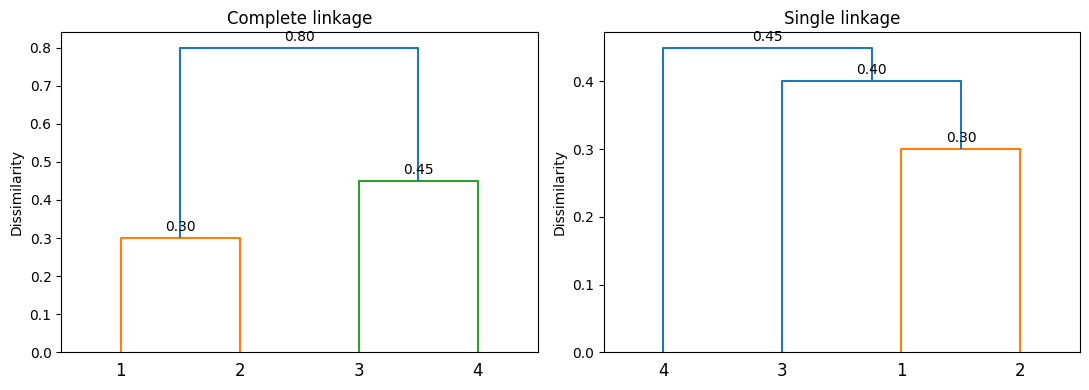

In [34]:
D = np.array([
    [0,    0.3, 0.4, 0.7],
    [0.3,  0,   0.5, 0.8],
    [0.4,  0.5, 0,   0.45],
    [0.7,  0.8, 0.45, 0]
])

distances = squareform(D)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, method, title in zip(
    axes,
    ["complete", "single"],
    ["Complete linkage", "Single linkage"]
):
    Z = linkage(distances, method=method)
    result = dendrogram(Z, labels=["1", "2", "3", "4"], ax=ax)

    for xs, ys in zip(result["icoord"], result["dcoord"]):
        height = ys[1]
        x = (xs[1] + xs[2]) / 2
        ax.annotate(f"{height:.2f}", (x, height),
                    xytext=(0, 5), textcoords="offset points",
                    ha="center")

    ax.set_title(title)
    ax.set_ylabel("Dissimilarity")

plt.tight_layout()
plt.show()

(c)

For part (c), cut the complete-linkage dendrogram at a height between 0.45 and 0.80. The two clusters are: Cluster 1 contains observations 1 and 2; Cluster 2 contains observations 3 and 4.

(d)

For part (d), cut the single-linkage dendrogram at a height between 0.40 and 0.45. The two clusters are: Cluster 1 contains observations 1, 2, and 3; Cluster 2 contains observation 4.